# 01 — Data: the WikiArt style subset

What the models will learn from, and what the data can and cannot tell us.

1. The images: 5 styles × 300 paintings, 128 × 128 RGB.
2. The fixed split used by every model (checked here once and for all).
3. What the metadata says, and the limitations that go on the data slide.
4. Colour statistics: why colour is a style cue, and why we don't use hue jitter.
5. What the models actually receive: normalisation, augmentation, input size.

Everything descriptive here uses the **training split only**; validation and test images are only counted, never looked at.

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.colors import rgb_to_hsv

sys.path.insert(0, "../src")
sys.path.insert(0, "../scripts")
from museum.data import CLASSES, IMAGE_DIR, ROOT, get_arrays, get_loaders, load_split, norm_stats
from validate_wikiart_subset import validate

torch.manual_seed(0)
FIG_DIR = ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("classes:", CLASSES)

classes: ['Baroque', 'Cubism', 'Impressionism', 'Pop_Art', 'Ukiyo_e']


In [2]:
# Every image decodes and matches metadata.csv and subset_info.json.
report = validate(IMAGE_DIR)
print({key: report[key] for key in ["total", "counts", "revision", "all_images_decoded"]})
assert report["total"] == 1500 and report["all_images_decoded"]

{'total': 1500, 'counts': {'Baroque': 300, 'Cubism': 300, 'Impressionism': 300, 'Pop_Art': 300, 'Ukiyo_e': 300}, 'revision': 'd559852d2b232e0fcf195e775866964f0564f2b5', 'all_images_decoded': True}


## 1. The images

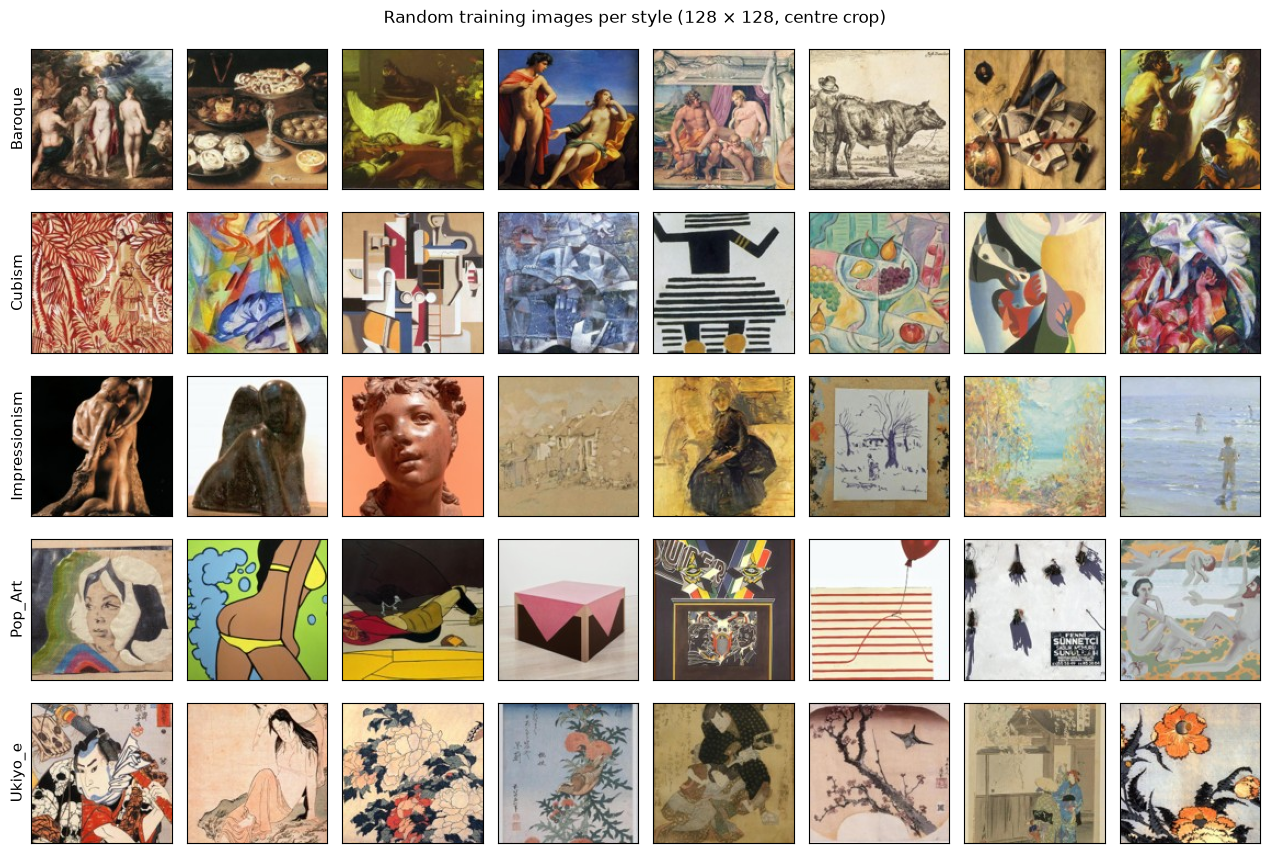

In [3]:
N_SHOW = 8
X_train, y_train = get_arrays(128, "train")
rng = np.random.default_rng(0)

fig, axes = plt.subplots(len(CLASSES), N_SHOW, figsize=(1.6 * N_SHOW, 1.75 * len(CLASSES)))
for row, style in enumerate(CLASSES):
    picks = rng.choice(np.flatnonzero(y_train == row), N_SHOW, replace=False)
    for ax, i in zip(axes[row], picks, strict=True):
        ax.imshow(X_train[i])
        ax.set(xticks=[], yticks=[])
    axes[row, 0].set_ylabel(style, fontsize=11)
fig.suptitle("Random training images per style (128 × 128, centre crop)")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_class_grid.png", dpi=150, bbox_inches="tight")
plt.show()

**What we see.** Each style has a recognisable look even at 128 px:
- **Baroque:** dark backgrounds, warm browns, dramatic light on bodies and still lifes.
- **Cubism:** fragmented, geometric shapes, but very varied within the class (from geometric still lifes to decorative patterns).
- **Impressionism:** light palettes and loose brushwork in landscapes, seascapes and figures.
- **Pop Art:** flat, bright colour areas with hard outlines.
- **Ukiyo-e:** woodblock prints on beige paper, flat colours, Japanese text and seals.

The labels are broader than "paintings", though: the grid also shows a Baroque etching, sketches, sculptures in the Impressionism row and 3-D objects in the Pop Art row (section 3).

## 2. The split

`data/split.csv` is written once by `scripts/make_split.py` (stratified, seed 0) and used by every model. These are the split checks of the definition of done.

In [4]:
split = load_split()
meta = pd.read_csv(IMAGE_DIR / "metadata.csv")

counts = pd.crosstab(split["label"], split["split"])[["train", "val", "test"]]
assert counts.sum().to_dict() == {"train": 1050, "val": 225, "test": 225}
assert (counts == pd.Series({"train": 210, "val": 45, "test": 45})).all().all()
assert split["path"].is_unique and set(split["path"]) == set(meta["path"])
print("split checks passed: 1050 / 225 / 225 images, 210 / 45 / 45 per style, no image in two splits")
counts

split checks passed: 1050 / 225 / 225 images, 210 / 45 / 45 per style, no image in two splits


split,train,val,test
label,,,
Baroque,210,45,45
Cubism,210,45,45
Impressionism,210,45,45
Pop_Art,210,45,45
Ukiyo_e,210,45,45


## 3. What the metadata says

In [5]:
by_style = meta.groupby("label")
kept_by_crop = meta[["orig_width", "orig_height"]].min(axis=1) / meta[["orig_width", "orig_height"]].max(axis=1)
limits = pd.DataFrame({
    "unknown artist (%)": by_style["artist"].apply(lambda s: 100 * (s == "Unknown Artist").mean()),
    "unknown genre (%)": by_style["genre"].apply(lambda s: 100 * (s == "Unknown Genre").mean()),
    "named artists": by_style["artist"].apply(lambda s: s[s != "Unknown Artist"].nunique()),
    "source files": by_style["shard"].nunique(),
    "painting kept by the crop (median %)": 100 * kept_by_crop.groupby(meta["label"]).median(),
}).round(0).astype(int)
limits

,unknown artist (%),unknown genre (%),named artists,source files,painting kept by the crop (median %)
label,,,,,
Baroque,96,84,7,3,73
Cubism,86,60,6,5,75
Impressionism,100,100,0,1,75
Pop_Art,100,100,0,2,76
Ukiyo_e,85,66,2,7,67


**Limitations (they go on the data slide).**
- **No artist, no genre for most images.** 85–100 % of the images of each style have no artist, and 60–100 % no genre.
  - We cannot split by artist, so near-identical works can sit in both train and test (checked by Antoine, N3).
  - Genre classification is not feasible on this subset.
- **Few source files.** Impressionism comes from a single source file and Pop Art from two, with no named artist at all. A model may learn the quirks of those files (scans, framing, photography) as well as the style.
- **The crop loses edges.** The square centre crop keeps about three quarters of a typical painting, and two thirds of the tall Ukiyo-e prints.

### Not only paintings

The class grid above shows sculptures in the Impressionism row and objects in the Pop Art row. We looked at the first 60 training images of these two styles one by one and listed the photographs of 3-D works (sculptures, reliefs, objects).

Impressionism: 4 of 60 inspected images are photographs of 3-D works (7%)
Pop_Art: 11 of 60 inspected images are photographs of 3-D works (18%)


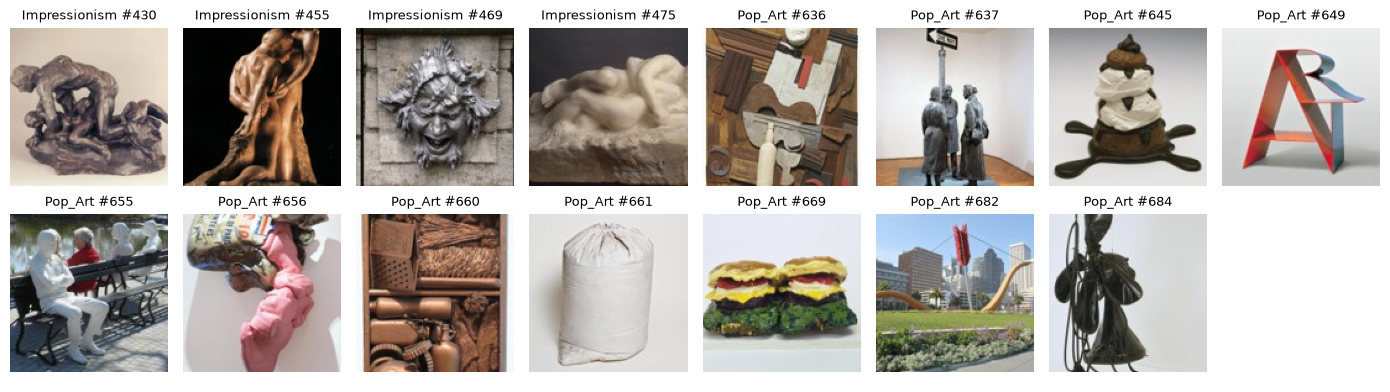

In [6]:
# Positions in get_arrays(128, "train"), fixed by split.csv; found by eye.
SPOTTED = {
    "Impressionism": [430, 455, 469, 475],
    "Pop_Art": [636, 637, 645, 649, 655, 656, 660, 661, 669, 682, 684],
}
for style, idx in SPOTTED.items():
    inspected = np.flatnonzero(y_train == CLASSES.index(style))[:60]
    assert set(idx) <= set(inspected), f"{style}: index outside the inspected images"
    print(f"{style}: {len(idx)} of 60 inspected images are photographs of 3-D works ({len(idx) / 60:.0%})")

shown = [i for idx in SPOTTED.values() for i in idx]
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, shown, strict=False):
    ax.imshow(X_train[i])
    ax.set_title(f"{CLASSES[y_train[i]]} #{i}", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_not_paintings.png", dpi=150, bbox_inches="tight")
plt.show()

**What we see.** About 1 in 15 Impressionism images and nearly 1 in 5 Pop Art images are photographs of sculptures or objects, usually on a plain background.
- **Risk:** a model can then score points with a shortcut ("object photographed on a white wall → Pop Art") that says nothing about painting style and won't help in front of a canvas. We look for it in the error analyses (A8, N5).
- **Decision:** we keep these images. The dataset and the split are fixed for every model, and visitors may point the guide at sculptures too. The proportions are estimates from 60 images per style.

## 4. Colour statistics (training images)

Per-image averages in HSV space, at 64 px (enough for image-level averages). Hue is only counted on coloured pixels (saturation > 0.15), since the hue of a grey pixel is meaningless.

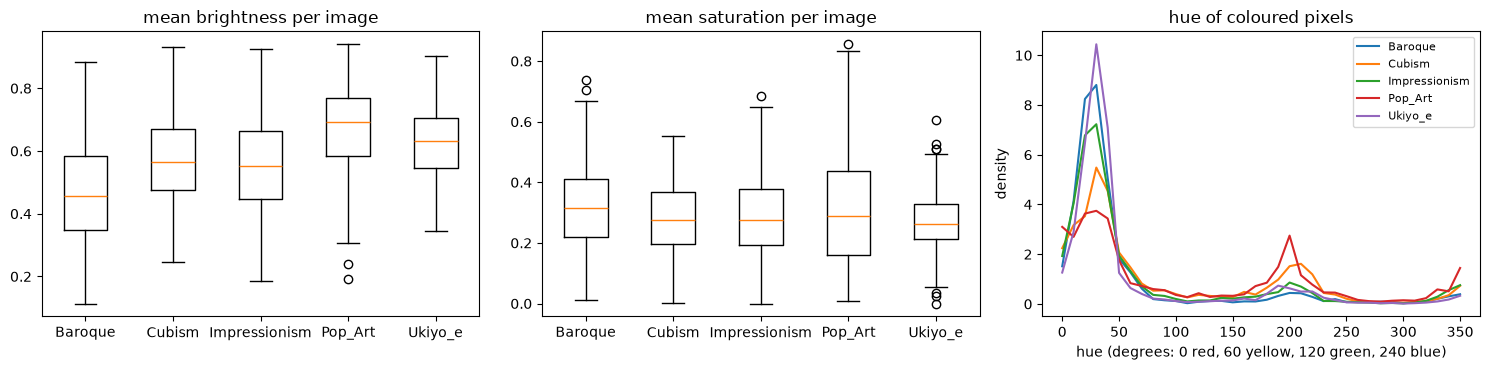

,brightness,saturation,near-greyscale images (sat < 0.08)
style,,,
Baroque,0.457,0.315,9
Cubism,0.565,0.275,10
Impressionism,0.553,0.276,8
Pop_Art,0.692,0.290,22
Ukiyo_e,0.631,0.263,5


In [7]:
X64, y64 = get_arrays(64, "train")
hsv = rgb_to_hsv(X64.astype(np.float32) / 255).reshape(len(X64), -1, 3)
colour = pd.DataFrame({
    "style": np.array(CLASSES)[y64],
    "brightness": hsv[..., 2].mean(axis=1),
    "saturation": hsv[..., 1].mean(axis=1),
})

hue_bins = np.linspace(0, 1, 37)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, column in zip(axes[:2], ["brightness", "saturation"], strict=True):
    ax.boxplot([colour.loc[colour["style"] == s, column] for s in CLASSES], tick_labels=CLASSES)
    ax.set_title(f"mean {column} per image")
for i, style in enumerate(CLASSES):
    pixels = hsv[y64 == i].reshape(-1, 3)
    hue = pixels[pixels[:, 1] > 0.15, 0]
    hist, _ = np.histogram(hue, bins=hue_bins, density=True)
    axes[2].plot(360 * hue_bins[:-1], hist, label=style)
axes[2].set(title="hue of coloured pixels", xlabel="hue (degrees: 0 red, 60 yellow, 120 green, 240 blue)",
            ylabel="density")
axes[2].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_colour_stats.png", dpi=150, bbox_inches="tight")
plt.show()

summary = colour.groupby("style")[["brightness", "saturation"]].median()
summary["near-greyscale images (sat < 0.08)"] = (colour["saturation"] < 0.08).groupby(colour["style"]).sum()
summary.round(3)

**What we see.**
- **Brightness separates some styles.** Baroque is the darkest (median 0.46) and Pop Art the brightest (0.69), but the boxes overlap widely, so brightness alone cannot classify.
- **Mean saturation is almost the same everywhere** (medians 0.26–0.32). Pop Art has the widest spread and the most near-greyscale images (22 of 210).
- **Hue carries more.** Every style peaks in warm orange-browns (varnish, aged paper), sharply for Baroque and Ukiyo-e, while Pop Art and Cubism have far more blue (around 200°) and red.

**Consequence.** Colour is a real but partial cue. It justifies the HSV-histogram features of the classical baseline (N2), and it is why the augmentation never jitters hue or saturation. The rest must come from shape and texture.

## 5. What the models receive

**Normalisation.** Per-channel mean and std of the training images only (`normalize="train"`); the pretrained ResNets use the ImageNet values instead.

In [8]:
mean, std = norm_stats("train", 128)
print("train mean (R, G, B):", np.round(mean, 3))
print("train std  (R, G, B):", np.round(std, 3))

train_dl, val_dl, _, _ = get_loaders(img_size=128, batch_size=256)
xb = torch.cat([x for x, _ in train_dl])
print("after normalisation, train mean:", xb.mean(dim=(0, 2, 3)).numpy().round(4),
      "std:", xb.std(dim=(0, 2, 3)).numpy().round(4))
assert xb.mean(dim=(0, 2, 3)).abs().max() < 1e-3 and (xb.std(dim=(0, 2, 3)) - 1).abs().max() < 1e-3

train mean (R, G, B): [0.546 0.5   0.44 ]
train std  (R, G, B): [0.272 0.263 0.26 ]


after normalisation, train mean: [0. 0. 0.] std: [1. 1. 1.]


**Augmentation** (training only): horizontal flip and a light random crop (80–100 % of the area, then resized back). No colour or hue jitter: section 4 shows colour carries style information, so changing it would blur the very cue we want the models to use.

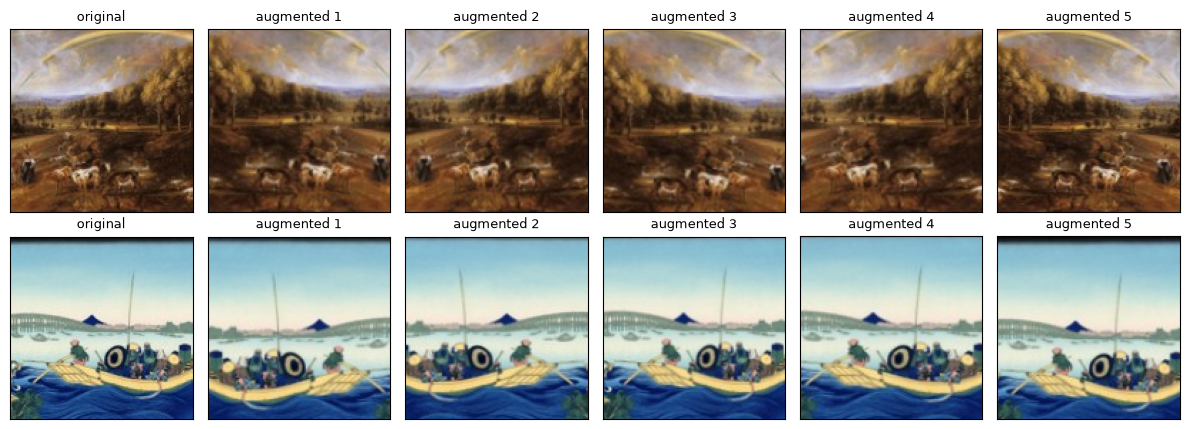

In [9]:
aug_dl, _, _, _ = get_loaders(img_size=128, augment=True)
dataset = aug_dl.dataset
mean_t, std_t = torch.tensor(mean)[:, None, None], torch.tensor(std)[:, None, None]


def to_image(x):
    return (x * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()


examples = [int(np.flatnonzero(y_train == c)[0]) for c in (0, 4)]
N_VIEWS = 5
fig, axes = plt.subplots(len(examples), N_VIEWS + 1, figsize=(2 * (N_VIEWS + 1), 2.2 * len(examples)))
torch.manual_seed(0)
for row, i in enumerate(examples):
    axes[row, 0].imshow(X_train[i])
    axes[row, 0].set_title("original", fontsize=9)
    for col in range(1, N_VIEWS + 1):
        axes[row, col].imshow(to_image(dataset[i][0]))
        axes[row, col].set_title(f"augmented {col}", fontsize=9)
for ax in axes.flat:
    ax.set(xticks=[], yticks=[])
fig.tight_layout()
fig.savefig(FIG_DIR / "01_augmentation.png", dpi=150, bbox_inches="tight")
plt.show()

**Input size.** The feed-forward network sees the image as one long vector, so its first layer grows with the square of the side: this is why notebook 02 compares 32, 64 and 128 px.

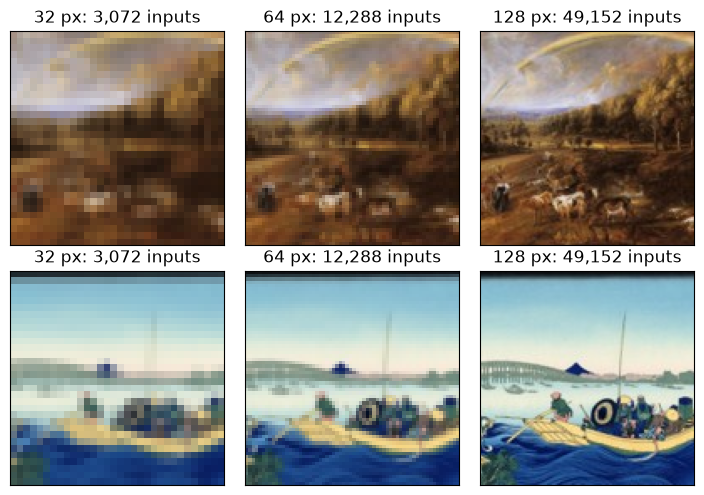

 32 px ->  3,072 input features; a first layer of 256 units has    786,688 parameters
 64 px -> 12,288 input features; a first layer of 256 units has  3,145,984 parameters
128 px -> 49,152 input features; a first layer of 256 units has 12,583,168 parameters


In [10]:
sizes = [32, 64, 128]
fig, axes = plt.subplots(len(examples), len(sizes), figsize=(2.4 * len(sizes), 2.5 * len(examples)))
for col, size in enumerate(sizes):
    X_size, _ = get_arrays(size, "train")
    for row, i in enumerate(examples):
        axes[row, col].imshow(X_size[i])
        axes[row, col].set(xticks=[], yticks=[], title=f"{size} px: {3 * size * size:,} inputs")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_input_sizes.png", dpi=150, bbox_inches="tight")
plt.show()

for size in sizes:
    print(f"{size:>3} px -> {3 * size * size:>6,} input features; a first layer of 256 units has "
          f"{(3 * size * size + 1) * 256:>10,} parameters")

## Summary

- **The data and the split.** 1,500 images in 5 balanced styles. The split (1,050 / 225 / 225, 210 / 45 / 45 per style) is checked here and shared by every model.
- **The cues.** Styles differ in colour (brightness, hue), but the distributions overlap, so the models must also use shape and texture.
- **Limitations for the data slide:**
  - missing artist and genre metadata
  - Impressionism and Pop Art come from only 1–2 source files
  - photographs of 3-D works (about 7 % of Impressionism, 18 % of Pop Art)
  - the square crop drops the edges
- **What the models receive.** Images normalised with training statistics only, horizontal flips and light crops as augmentation, and, for the feed-forward network, 3,072 to 49,152 inputs depending on the image size (notebook 02).